<a href="https://colab.research.google.com/github/autoinganno/lab3/blob/main/3_before.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

`Дисциплина: Методы и технологии машинного обучения`   
`Уровень подготовки: бакалавриат`   
`Направление подготовки: 01.03.02 Прикладная математика и информатика`     




# Лабораторная работа №3: Линейные модели. Кросс-валидация.

В практических примерах ниже показано:   

* как пользоваться инструментами предварительного анализа для поиска линейных взаимосвязей
* как строить и интерпретировать линейные модели с логарифмами  
* как оценивать точность моделей с перекрёстной проверкой (LOOCV, проверка по блокам)

*Модели*: множественная линейная регрессия
*Данные*: `Boston_for_lab` (Вариант 5: зависимая `medv`, объясняющие `indus`, `crim`, фиктивная `tax_over_400`)

# Указания к выполнению


## Загружаем пакеты

In [1]:
# загрузка пакетов: инструменты --------------------------------------------
#  работа с массивами
import numpy as np
#  фреймы данных
import pandas as pd
#  графики
import matplotlib as mpl
#  стили и шаблоны графиков на основе matplotlib
import seaborn as sns
# перекодировка категориальных переменных
from sklearn.preprocessing import LabelEncoder
#  тест Шапиро-Уилка на нормальность распределения
from scipy.stats import shapiro
#  для таймера
import time

# загрузка пакетов: модели -------------------------------------------------
#  линейные модели
import sklearn.linear_model as skl_lm
#  расчёт MSE
from sklearn.metrics import mean_squared_error
#  кросс-валидация
from sklearn.model_selection import train_test_split, LeaveOneOut
from sklearn.model_selection import KFold, cross_val_score
#  полиномиальные модели
from sklearn.preprocessing import PolynomialFeatures

In [3]:
# константы
#  ядро для генератора случайных чисел
my_seed = 5
#  создаём псевдоним для короткого обращения к графикам
plt = mpl.pyplot
# настройка стиля и отображения графиков
#  примеры стилей и шаблонов графиков:
#  http://tonysyu.github.io/raw_content/matplotlib-style-gallery/gallery.html
mpl.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
# раскомментируйте следующую строку, чтобы посмотреть палитру
# sns.color_palette("Set2")

## Загружаем данные

Набор данных `Boston_for_lab` в формате .csv доступен для загрузки по адресу: <https://raw.githubusercontent.com/ania607/ML/main/data/Boston_for_lab.csv>.

In [5]:
# читаем таблицу из файла .csv во фрейм
fileURL ="https://raw.githubusercontent.com/ania607/ML/main/data/Boston_for_lab.csv"
DF_raw =pd.read_csv(fileURL)

# выясняем размерность фрейма
print('Число строк и столбцов в наборе данных:\n', DF_raw.shape)

Число строк и столбцов в наборе данных:
 (506, 15)


In [9]:
# первые 5 строк фрейма
DF_raw.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv,tax_over_400
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0,0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6,0
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7,0
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4,0
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2,0


"""Здесь:
* **medv** – медианная стоимость домов, тыс. долл. США (зависимая переменная);
* **crim** – уровень преступности на душу населения по району;
* **indus** – доля акров, не связанных с розничной торговлей, на город;
* **tax_over_400** – фиктивная переменная: 1, если полная ставка налога на имущество на $10000 превышает 400, иначе 0.

In [6]:
# типы столбцов фрейма
DF_raw.dtypes

,0
crim,float64
zn,float64
indus,float64
chas,int64
nox,float64
rm,float64
age,float64
dis,float64
rad,int64
tax,int64


Проверим, нет ли в таблице пропусков.  

In [10]:
# считаем пропуски в каждом столбце
DF_raw.isnull().sum()

,0
crim,0
zn,0
indus,0
chas,0
nox,0
rm,0
age,0
dis,0
rad,0
tax,0


Пропусков не обнаружено.  

In [12]:
# фиксирую переменную tax_over_400

DF_raw['tax_over_400'] = (DF_raw['tax'] > 400).astype(int)

In [13]:
# объединяем с исходным фреймом
DF_all = DF_raw[['medv', 'indus', 'crim', 'tax_over_400']].copy()

print('Размерность после фильтрации:', DF_all.shape)
DF_all.head()

Размерность после фильтрации: (506, 4)


,medv,indus,crim,tax_over_400
0,24.0,2.31,0.00632,0
1,21.6,7.07,0.02731,0
2,34.7,7.07,0.02729,0
3,33.4,2.18,0.03237,0
4,36.2,2.18,0.06905,0


In [14]:
# удаляю исходный фрейм
del DF_raw

Прежде чем переходить к анализу данных, разделим фрейм на две части: одна (80%) станет основой для обучения моделей, на вторую (20%) мы сделаем прогноз по лучшей модели.  

In [20]:
# данные для построения моделей и прогноза
DF, DF_predict =  train_test_split(DF_all, test_size=0.2, random_state=my_seed)



## Предварительный анализ данных   

### Считаем описательные статистики   

Рассчитаем описательные статистики для непрерывных переменных. Из таблицы ниже можно видеть, что переменная `medv` (зависимая) имеет заметный разброс. Переменная `crim` сильно скошена вправо (есть районы с очень высоким уровнем преступности), а `indus` имеет значения от минимальных до максимальных.  

In [21]:
# описательные статистики для непрерывных переменных
DF[['medv', 'indus', 'crim']].describe()

,medv,indus,crim
count,404.000000,404.000000,404.000000
mean,22.646782,10.845124,3.550812
std,9.279809,6.737307,8.688347
min,5.000000,0.460000,0.006320
25%,17.075000,5.130000,0.079575
50%,21.200000,8.560000,0.242170
75%,25.000000,18.100000,3.674808
max,50.000000,27.740000,88.976200


### Строим графики  

Посмотрим на графики взаимного разброса непрерывных переменных.

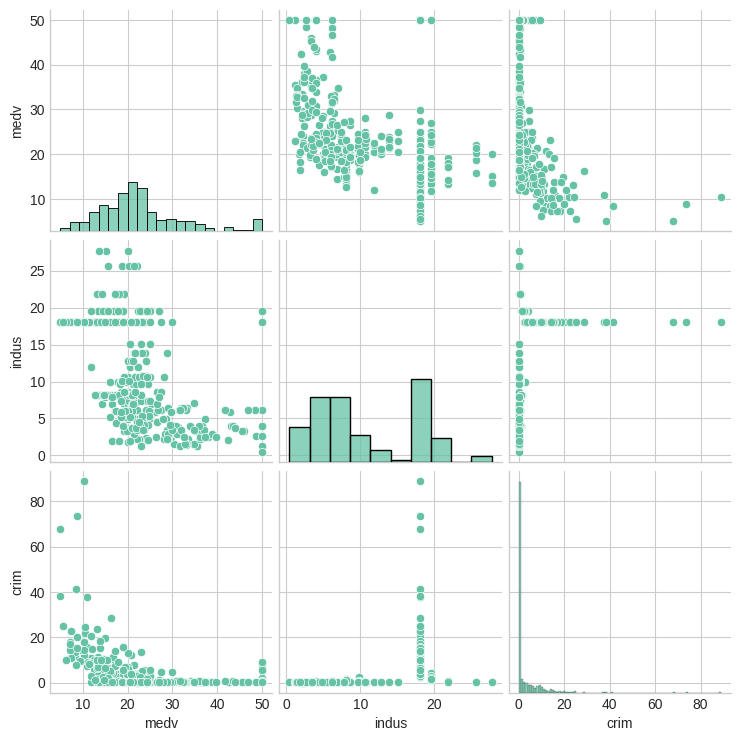

In [22]:
# матричный график разброса
sns.pairplot(DF[['medv', 'indus', 'crim']])
plt.show()

"""Судя по этим графикам:  
* распределение зависимой `medv` близко к нормальному, но имеет некоторые отклонения;  
* переменная `crim` имеет ярко выраженную правостороннюю асимметрию (много нулевых или близких к нулю значений);  
* между `medv` и `crim` прослеживается обратная связь (чем выше преступность, тем ниже стоимость);  
* между `medv` и `indus` также наблюдается обратная зависимость.  



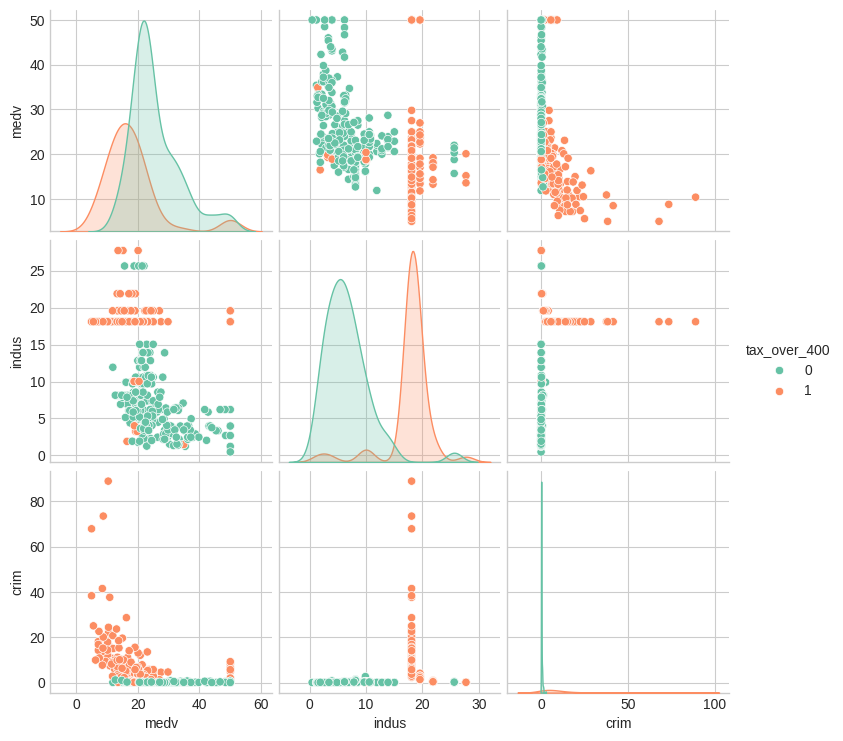

In [23]:
# График с учетом фиктивной переменной
sns.pairplot(DF[['medv', 'indus', 'crim', 'tax_over_400']], hue='tax_over_400')
plt.show()

Посмотрим на корреляционные матрицы

In [25]:
# Корреляционная матрица
corr_mat = DF[['medv', 'indus', 'crim']].corr()
corr_mat.style.background_gradient(cmap='coolwarm').format(precision=2)

,medv,indus,crim
medv,1.00,-0.48,-0.39
indus,-0.48,1.00,0.42
crim,-0.39,0.42,1.00




### Логарифмируем зависимую переменную  

Важным допущением линейной регрессии является нормальность зависимой переменной. Чтобы добиться нормального распределения, используют логарифмирование либо преобразование Бокса-Кокса. В этой лабораторной остановимся на логарифмировании.

In [26]:
# логарифмируем зависимую переменную
DF['log_medv'] = np.log(DF['medv'])

# описательные статистики для непрерывных показателей
DF[['medv', 'log_medv', 'indus', 'crim']].describe()


,medv,log_medv,indus,crim
count,404.000000,404.000000,404.000000,404.000000
mean,22.646782,3.038959,10.845124,3.550812
std,9.279809,0.410528,6.737307,8.688347
min,5.000000,1.609438,0.460000,0.006320
25%,17.075000,2.837612,5.130000,0.079575
50%,21.200000,3.054001,8.560000,0.242170
75%,25.000000,3.218876,18.100000,3.674808
max,50.000000,3.912023,27.740000,88.976200


Проведём формальные тесты на нормальность.  

In [29]:
#  Тест Шапиро-Уилка на нормальность
for col in ['medv', 'log_medv']:
    stat, p = shapiro(DF[col])
    print(col, 'Statistics=%.2f, p=%.4f' % (stat, p))
    alpha = 0.05
    if p > alpha:
        print('Распределение нормально (H0 не отклоняется)\n')
    else:
        print('Распределение не нормально (H0 отклоняется)\n')

medv Statistics=0.92, p=0.0000
Распределение не нормально (H0 отклоняется)

log_medv Statistics=0.98, p=0.0000
Распределение не нормально (H0 отклоняется)



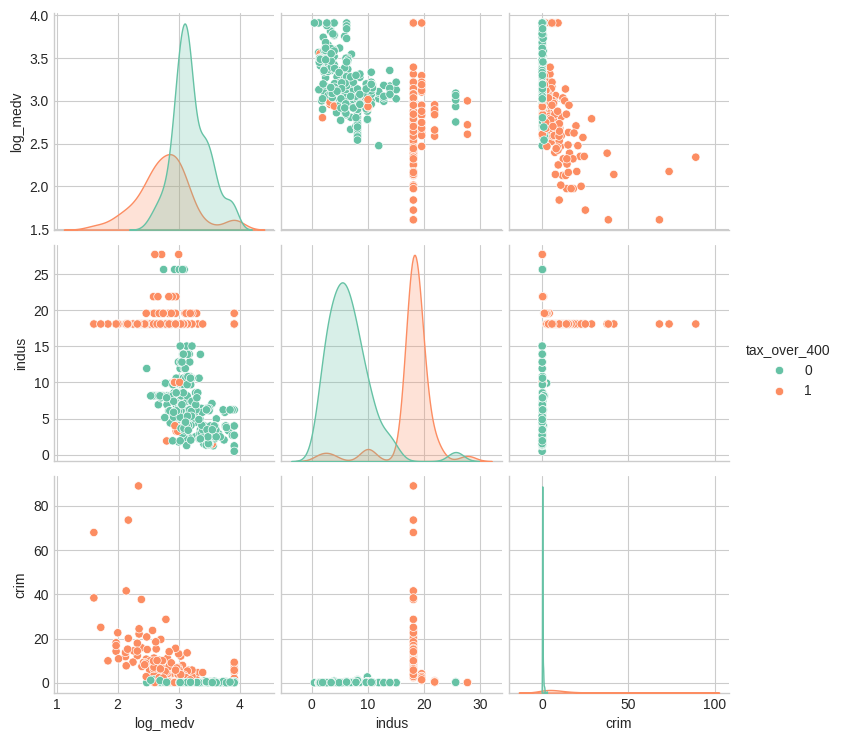

In [30]:
# График разброса для логарифма
sns.pairplot(DF[['log_medv', 'indus', 'crim', 'tax_over_400']], hue='tax_over_400')
plt.show()

## Строим модели регрессии

### Спецификация моделей  
По итогам предварительного анализа данных можно предложить следующие спецификации линейных регрессионных моделей (где \(X_1\) = `crim`, \(X_2\) = `indus`, \(D\) = `tax_over_400`):  

1. `fit_lm_1`: $\(\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot D + \hat{\beta_2} \cdot X_1 + \hat{\beta_3} \cdot X_2\)$
2. `fit_lm_2`: $\(\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot D + \hat{\beta_2} \cdot X_1 + \hat{\beta_3} \cdot X_2 + \hat{\beta_4} \cdot (X_1 \cdot D)\)$
3. `fit_lm_3`: $\(\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot D + \hat{\beta_2} \cdot X_1 + \hat{\beta_3} \cdot X_2 + \hat{\beta_4} \cdot (X_2 \cdot D)\)$
4. `fit_lm_4`: $\(\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot D + \hat{\beta_2} \cdot X_1 + \hat{\beta_3} \cdot X_2 + \hat{\beta_4} \cdot (X_1 \cdot D) + \hat{\beta_5} \cdot (X_2 \cdot D)\)$

1. `fit_lm_1_log` ... `fit_lm_4_log`: то же самое, но для зависимой \(\hat{log\_medv}\)  

Кроме того, добавим в сравнение модели зависимости `medv` и `log_medv` от всех объясняющих переменных и взаимодействия $\(X_1 \cdot X_2\)$: `fit_lm_0` и `fit_lm_0_log` соответственно.  

### Обучение и интерпретация  

Создаём матрицы значений объясняющих переменных ( \(X\) ) и вектора значений зависимой ( \(y\) ) для всех моделей.  

In [31]:
# Создаем матрицы для разных спецификаций
# df1: базовые переменные (модели 1, 6)
df1 = DF[['medv', 'crim', 'indus', 'tax_over_400']].copy()

# df2: + взаимодействие crim и дамми (модели 2, 7)
df2 = df1.copy()
df2['crim_tax'] = df2['crim'] * df2['tax_over_400']

# df3: + взаимодействие indus и дамми (модели 3, 8)
df3 = df1.copy()
df3['indus_tax'] = df3['indus'] * df3['tax_over_400']

# df4: + оба взаимодействия (модели 4, 9)
df4 = df1.copy()
df4['crim_tax'] = df4['crim'] * df4['tax_over_400']
df4['indus_tax'] = df4['indus'] * df4['tax_over_400']

# df0: все переменные + взаимодействие crim и indus (модели 5, 10)
df0 = df4.copy()
df0['crim_indus'] = df0['crim'] * df0['indus']

print("Фрейм df4 (пример всех переменных):")
df4.head()

Фрейм df4 (пример всех переменных):


,medv,crim,indus,tax_over_400,crim_tax,indus_tax
33,13.1,1.15172,8.14,0,0.00000,0.0
283,50.0,0.01501,1.21,0,0.00000,0.0
418,8.8,73.53410,18.10,1,73.53410,18.1
502,20.6,0.04527,11.93,0,0.00000,0.0
402,12.1,9.59571,18.10,1,9.59571,18.1


Построим модели от всех объясняющих переменных на всех наблюдениях `DF`, чтобы проинтерпретировать параметры. В модели для зависимой переменной `medv` интерпретация стандартная:  

1. Константа – базовый уровень зависимой переменной, когда все объясняющие равны 0.  
2. Коэффициент при объясняющей переменной $X$ показывает, на сколько своих единиц измерения изменится $Y$, если $X$ увеличится на одну свою единицу измерения.  


In [32]:
# Построение и интерпретация модели на всех переменных (medv)
lm = skl_lm.LinearRegression()

X = df0.drop(['medv'], axis=1)
y = df0.medv.values.reshape(-1, 1)
fit_lm_0 = lm.fit(X, y)
print('модель fit_lm_0:\n',
      'константа ', np.around(fit_lm_0.intercept_, 3),
      '\n объясняющие ', list(X.columns.values),
      '\n коэффициенты ', np.around(fit_lm_0.coef_, 3))

модель fit_lm_0:
 константа  [31.144] 
 объясняющие  ['crim', 'indus', 'tax_over_400', 'crim_tax', 'indus_tax', 'crim_indus'] 
 коэффициенты  [[-1.249 -0.723 -8.542  6.624  0.607 -0.312]]


In [33]:
# Оценка MSE на обучающей для medv
y_pred = fit_lm_0.predict(X)
MSE = sum((y - y_pred.reshape(-1, 1))**2) / len(y)
np.sqrt(MSE)

array([7.76753717])

С интерпретацией модели на логарифме $Y$ дела обстоят сложнее:  
1. Константу сначала надо экспоненциировать, далее интерпретировать как для обычной модели регрессии.  
1. Коэффициент при $X$ нужно экспоненциировать, затем вычесть из получившегося числа 1, затем умножить на 100. Результат показывает, на сколько процентов изменится (увеличится, если коэффициент положительный, и уменьшится, если отрицательный) зависимая переменная, если $X$ увеличится на одну свою единицу измерения.  

In [35]:
# Модель на логарифме
X = df0.drop(['medv'], axis=1)
y = np.log(df0.medv).values.reshape(-1, 1)
fit_lm_0_log = lm.fit(X, y)
print('модель fit_lm_0_log:\n',
      'константа ', np.around(fit_lm_0_log.intercept_, 3),
      '\n объясняющие ', list(X.columns.values),
      '\n коэффициенты ', np.around(fit_lm_0_log.coef_, 3))

модель fit_lm_0_log:
 константа  [3.418] 
 объясняющие  ['crim', 'indus', 'tax_over_400', 'crim_tax', 'indus_tax', 'crim_indus'] 
 коэффициенты  [[-0.159 -0.026 -0.325  0.268  0.018 -0.007]]


In [36]:
# Пересчет коэффициентов логарифмической модели в проценты
np.around((np.exp(fit_lm_0_log.coef_) - 1) * 100, 1)

array([[-14.7,  -2.6, -27.7,  30.7,   1.8,  -0.7]])

In [37]:
# Оценка MSE на обучающей для log(medv)
y_pred = fit_lm_0_log.predict(X)
MSE_log = sum((np.exp(y) - np.exp(y_pred).reshape(-1, 1))**2) / len(y)
np.sqrt(MSE_log)

array([7.78876119])

In [38]:
print('MSE_train модели для medv меньше MSE_train',
     'модели для log(medv) в ', np.around(MSE_log / MSE, 1), 'раз')

MSE_train модели для medv меньше MSE_train модели для log(medv) в  [1.] раз


### Оценка точности

#### LOOCV  

Сделаем перекрёстную проверку точности моделей по одному наблюдению.  

In [39]:
#  Перекрёстная проверка по 10 блокам для medv
folds = 10
r_state = np.arange(my_seed, my_seed + 9)

scores = list()
tic = time.perf_counter()
i = 0
for df in [df0, df1, df2, df3, df4]:
    X = df.drop(['medv'], axis=1)
    y = df['medv'].values.reshape(-1, 1)
    kf_10 = KFold(n_splits=folds, random_state=r_state[i], shuffle=True)
    score = cross_val_score(lm, X, y, cv=kf_10, scoring='neg_mean_squared_error').mean()
    scores.append(score)
    i += 1
toc = time.perf_counter()
print(f"Расчёты методом CV по 10 блокам заняли {toc - tic:0.2f} секунд")

Расчёты методом CV по 10 блокам заняли 0.63 секунд


In [40]:
# Перекрёстная проверка по 10 блокам для log(medv)
scores_log = list()
tic = time.perf_counter()
i = 0
for df in [df0, df1, df2, df3, df4]:
    X = df.drop(['medv'], axis=1)
    y = np.log(df['medv']).values.reshape(-1, 1)
    kf_10 = KFold(n_splits=folds, random_state=r_state[i], shuffle=True)
    score = cross_val_score(lm, X, y, cv=kf_10, scoring='neg_mean_squared_error').mean()
    scores_log.append(score)
    i += 1
toc = time.perf_counter()
print(f"Расчёты методом CV по 10 блокам заняли {toc - tic:0.2f} секунд")

Расчёты методом CV по 10 блокам заняли 0.44 секунд


In [43]:
# Вывод ошибок
print("MSE для medv:", [np.around(-x, 2) for x in scores])
print("MSE для log(medv):", [np.around(-x, 3) for x in scores_log])

MSE для medv: [np.float64(62.65), np.float64(64.06), np.float64(63.22), np.float64(62.82), np.float64(62.73)]
MSE для log(medv): [np.float64(0.1), np.float64(0.104), np.float64(0.101), np.float64(0.103), np.float64(0.102)]


In [44]:
#  Определение лучшей модели для medv
fits = ['fit_lm_0', 'fit_lm_1', 'fit_lm_2', 'fit_lm_3', 'fit_lm_4']
best_medv_idx = scores.index(max(scores))
print('Наименьшая ошибка на тестовой с k-fold10 у модели',
      fits[best_medv_idx],
      ':\nMSE_kf10 =', np.around(-max(scores), 0))

Наименьшая ошибка на тестовой с k-fold10 у модели fit_lm_0 :
MSE_kf10 = 63.0


In [45]:
#  Определение лучшей модели для log(medv)
best_log_idx = scores_log.index(max(scores_log))
print('Наименьшая ошибка на тестовой с k-fold10 у модели',
      fits[best_log_idx],
      ':\nMSE_kf10 =', np.around(-max(scores_log), 3))

Наименьшая ошибка на тестовой с k-fold10 у модели fit_lm_0 :
MSE_kf10 = 0.1


In [47]:
#  Прогноз по лучшей модели для medv
best_df_medv = [df0, df1, df2, df3, df4][best_medv_idx]

# Обучаем модель на всех обучающих данных
X_train = best_df_medv.drop(['medv'], axis=1)
y_train = best_df_medv.medv.values.reshape(-1, 1)
fit_best_medv = lm.fit(X_train, y_train)

# Подготавливаем тестовые данные
X_test = DF_predict.copy()
if 'crim_tax' in best_df_medv.columns:
    X_test['crim_tax'] = X_test['crim'] * X_test['tax_over_400']
if 'indus_tax' in best_df_medv.columns:
    X_test['indus_tax'] = X_test['indus'] * X_test['tax_over_400']
if 'crim_indus' in best_df_medv.columns:
    X_test['crim_indus'] = X_test['crim'] * X_test['indus']
X_test = X_test.drop(['medv'], axis=1)

# ИСПРАВЛЕНИЕ: выравниваем порядок столбцов по X_train
X_test = X_test[X_train.columns]

y_test_medv = DF_predict[['medv']].values.reshape(-1, 1)

# Прогноз
y_pred_medv = fit_best_medv.predict(X_test)

# Ошибка
MSE_test_medv = sum((y_test_medv - y_pred_medv.reshape(-1, 1))**2) / len(y_test_medv)
print('MSE лучшей модели для medv на отложенных наблюдениях = %.2f' % MSE_test_medv)

MSE лучшей модели для medv на отложенных наблюдениях = 53.41


/tmp/ipykernel_813/3907146620.py:29: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print('MSE лучшей модели для medv на отложенных наблюдениях = %.2f' % MSE_test_medv)


In [49]:
#  Прогноз по лучшей модели для log(medv)
best_df_log = [df0, df1, df2, df3, df4][best_log_idx]

# Обучаем модель на всех обучающих данных
X_train_log = best_df_log.drop(['medv'], axis=1)
y_train_log = np.log(best_df_log.medv).values.reshape(-1, 1)
fit_best_log = lm.fit(X_train_log, y_train_log)

# Подготавливаем тестовые данные
X_test_log = DF_predict.copy()

# Создаём ВСЕ возможные взаимодействия (лишние потом отфильтруем)
X_test_log['crim_tax'] = X_test_log['crim'] * X_test_log['tax_over_400']
X_test_log['indus_tax'] = X_test_log['indus'] * X_test_log['tax_over_400']
X_test_log['crim_indus'] = X_test_log['crim'] * X_test_log['indus']

# Удаляем зависимую переменную перед фильтрацией
if 'medv' in X_test_log.columns:
    X_test_log = X_test_log.drop(['medv'], axis=1)

# Выравниваем столбцы строго по обучающей матрице (и порядок, и состав)
X_test_log = X_test_log[X_train_log.columns]

# Проверка (можно удалить после отладки)
print("Столбцы X_train_log:", list(X_train_log.columns))
print("Столбцы X_test_log: ", list(X_test_log.columns))

# Целевые значения в логарифме
y_test_log = np.log(DF_predict[['medv']].values.reshape(-1, 1))

# Прогноз
y_pred_log = fit_best_log.predict(X_test_log)

# Ошибка (сравниваем на исходной шкале)
MSE_test_log = sum((np.exp(y_test_log) - np.exp(y_pred_log).reshape(-1, 1))**2) / len(y_test_log)
print('MSE лучшей модели для log(medv) на отложенных наблюдениях = %.2f' % MSE_test_log)

Столбцы X_train_log: ['crim', 'indus', 'tax_over_400', 'crim_tax', 'indus_tax', 'crim_indus']
Столбцы X_test_log:  ['crim', 'indus', 'tax_over_400', 'crim_tax', 'indus_tax', 'crim_indus']
MSE лучшей модели для log(medv) на отложенных наблюдениях = 54.63


/tmp/ipykernel_813/2537954198.py:36: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print('MSE лучшей модели для log(medv) на отложенных наблюдениях = %.2f' % MSE_test_log)


In [50]:
# Сравнение относительных ошибок (в %)
print('Относительная ошибка модели medv:', np.sqrt(MSE_test_medv) / np.mean(DF_predict[['medv']]) * 100, '%')
print('Относительная ошибка модели log(medv):', np.sqrt(MSE_test_log) / np.mean(DF_predict[['medv']]) * 100, '%')

Относительная ошибка модели medv: [33.09593571] %
Относительная ошибка модели log(medv): [33.47147572] %


In [51]:
# Вывод выбранной модели и её коэффициентов (на примере лучшей для medv или log_medv)
print(f"Лучшая модель на отложенных данных: {fits[best_medv_idx]}")
print('Уравнение регрессии:')
print('Константа:', np.around(fit_best_medv.intercept_, 3))
print('Коэффициенты:')
for col, coef in zip(X_train.columns, fit_best_medv.coef_[0]):
    print(f"  {col}: {np.around(coef, 3)}")

Лучшая модель на отложенных данных: fit_lm_0
Уравнение регрессии:
Константа: [3.418]
Коэффициенты:
  crim: -0.159
  indus: -0.026
  tax_over_400: -0.325
  crim_tax: 0.268
  indus_tax: 0.018
  crim_indus: -0.007


### Интерпретация лучшей модели

В зависимости от того, какая модель оказалась точнее на отложенных данных (для `medv` или для `log_medv`), интерпретация будет следующей:

* **Если лучшая модель для `medv` (обычная регрессия):**
  * Коэффициент при `crim` показывает, на сколько тысяч долларов изменится медианная стоимость дома при увеличении уровня преступности на 1 единицу (при прочих равных).
  * Коэффициент при `tax_over_400` показывает, на сколько тысяч долларов отличаются дома в районах с высоким налогом (>400) по сравнению с районами с низким налогом (<=400).
  * Коэффициент при взаимодействии `crim_tax` (если есть) показывает, как меняется влияние преступности на стоимость дома в районах с высоким налогом.

* **Если лучшая модель для `log_medv` (логарифмическая регрессия):**
  * Коэффициенты нужно преобразовать по формуле: (exp(β) - 1) * 100%.
  * Полученное значение покажет, на сколько **процентов** изменится медианная стоимость дома при увеличении соответствующей переменной на 1 единицу.

# Источники

1. *James G., Witten D., Hastie T. and Tibshirani R.*  An Introduction to Statistical Learning with Applications in R. URL: [http://www-bcf.usc.edu/~gareth/ISL/ISLR%20First%20Printing.pdf](https://drive.google.com/file/d/15PdWDMf9hkfP8mrCzql_cNiX2eckLDRw/view?usp=sharing)     
1. Рашка С. Python и машинное обучение: крайне необходимое пособие по новейшей предсказательной аналитике, обязательное для более глубокого понимания методологии машинного обучения / пер. с англ. А.В. Логунова. – М.: ДМК Пресс, 2017. – 418 с.: ил.
1. Interpreting Log Transformations in a Linear Model / virginia.edu. URL: <https://data.library.virginia.edu/interpreting-log-transformations-in-a-linear-model/>  
1. Python Timer Functions: Three Ways to Monitor Your Code / realpython.com. URL: <https://realpython.com/python-timer/>  